# 02 - Armenian through a tokenizer's eyes

The practical after **LLM-1 (Tokenization)**. Three parts:

1. **Build one.** A byte-level BPE tokenizer from scratch, trained on Armenian Wikipedia, in about
   30 lines.
2. **Audit the pros.** The same Armenian text through 14 real tokenizers from 2018 to 2026: what each
   one charges for Armenian, and why.
3. **Hunt a glitch.** Find Armenian tokens that GPT-4o's tokenizer owns but real text never produces,
   then ask three OpenAI models to say them.

**Predict** lines ask the room to commit to a guess before the next cell runs. Each part ends with a
**Remember** line.

**Running it:** 8 to 14 minutes from top to bottom on the instructor's laptop; the slow cells say how long they take on their
first line. The data (Armenian and English Wikipedia samples) downloads once into `data/`. Part 3
makes 63 calls to paid models through OpenRouter (about $0.0005 in total); it needs
`OPENROUTER_API_KEY` in the repository's `.env` file.

## Setup

Two tokenizer libraries, and no model weights anywhere: `tiktoken` for OpenAI's tokenizers, and
Hugging Face's `tokenizers` for everyone else's (each is one `tokenizer.json` file of a few MB).

In [1]:
# ~5-25 s
import json
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import regex
import requests
import tiktoken
from huggingface_hub import hf_hub_download
from tokenizers import Tokenizer

DATA, RESULTS = Path("data"), Path("results")
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
ARMENIAN = re.compile(r"[԰-֏ﬓ-ﬗ]")   # the Armenian block and its 5 ligatures
RED, BLUE, ORANGE = "#D90012", "#0033A0", "#F2A800"
R = {}   # every number this notebook reports, saved to results/ at the end

The text: a sample of Armenian Wikipedia (20 million characters) and of English Wikipedia (5
million), from the November 2023 dump. The first run downloads them into `data/`; later runs read the
files.

In [2]:
# ~10 s (a few minutes on the first run: the download)
SEP = "\n\n=====ARTICLE_BREAK=====\n\n"


def wiki_sample(lang, n_chars):
    # whole Wikipedia articles until n_chars, cached in data/
    cache = DATA / f"{lang}_wiki_{n_chars}.txt"
    if not cache.exists():
        import datasets                              # only needed for the download
        stream = datasets.load_dataset("wikimedia/wikipedia", f"20231101.{lang}",
                                       split="train", streaming=True)
        articles, total = [], 0
        for ex in stream:
            articles.append(ex["text"])
            total += len(ex["text"])
            if total >= n_chars:
                break
        cache.write_text(SEP.join(articles), encoding="utf-8")
    return [a for a in cache.read_text(encoding="utf-8").split(SEP) if a.strip()]


hy_articles = wiki_sample("hy", 20_000_000)
en_articles = wiki_sample("en", 5_000_000)
print(f"Armenian: {len(hy_articles):,} articles, {sum(map(len, hy_articles)):,} characters")
print(f"English:  {len(en_articles):,} articles, {sum(map(len, en_articles)):,} characters")

Armenian: 3,149 articles, 20,037,131 characters
English:  152 articles, 5,007,358 characters


Wikipedia in two languages is not the same text, so it cannot say what the **same meaning** costs in
each. For that we need a parallel corpus: NTREX-128, 1,997 English news sentences professionally
translated into 128 languages, Armenian among them (two small text files).

In [3]:
def ntrex(path):
    return Path(hf_hub_download("davidstap/NTREX", path, repo_type="dataset")).read_text(encoding="utf-8").splitlines()


par_hy = ntrex("data/hye_Armn/newstest2019-ref.hye.txt")
par_en = ntrex("data/eng_Latn/newstest2019-ref.eng.txt")
assert len(par_hy) == len(par_en)
print(f"{len(par_hy):,} sentence pairs; characters: Armenian {sum(map(len, par_hy)):,}, "
      f"English {sum(map(len, par_en)):,}")
print(par_en[1])
print(par_hy[1])

1,997 sentence pairs; characters: Armenian 264,715, English 247,720
There is consternation among some AMs at a suggestion their title should change to MWPs (Member of the Welsh Parliament).
Ասամբլեայի որոշ անդամների մոտ վախ կա MWPs (Ուելսի խորհրդարանի անդամ) անվանափոխության առաջարկի վերաբերյալ:


And LLM-1's line, with its English gloss (the "Armenian tax" slide):

In [4]:
LINE = Path("../../ml/13_rnns/py_src/data/armenian_line.txt").read_text(encoding="utf-8").strip()
GLOSS = "I watch all of this in silence, and the connoisseurs speak inside me."
print(LINE)
print(GLOSS)

Ես այս ամենին նայում եմ լուռ, և գիտակներ են խոսում իմ մեջ
I watch all of this in silence, and the connoisseurs speak inside me.


# Part 1 - Build one

LLM-1 ran BPE by hand on a toy corpus. Here the same algorithm runs on real Armenian, and we watch
what it does with an alphabet that UTF-8 stores in **two bytes per letter**.

## 1.1 Armenian in bytes

A byte-level tokenizer starts from the 256 possible bytes (LLM-1, "Why 256"). An English letter is
one byte. An Armenian letter?

In [5]:
for ch in ["a", "ա", "Ա", "։"]:
    b = ch.encode("utf-8")
    print(f"{ch!r}: {len(b)} byte(s), {list(b)}")

'a': 1 byte(s), [97]
'ա': 2 byte(s), [213, 161]
'Ա': 2 byte(s), [212, 177]
'։': 2 byte(s), [214, 137]


Two bytes each, and the first byte is always one of three (212, 213 or 214): every Armenian letter
in the 0530-058F block starts the same way.

**Predict:** GPT-4's tokenizer has 100,000 tokens. How many does it spend on LLM-1's line?

In [6]:
gpt4 = tiktoken.get_encoding("cl100k_base")
n_chars, n_bytes = len(LINE), len(LINE.encode("utf-8"))
n_gpt4 = len(gpt4.encode(LINE))
print(f"the line: {n_chars} characters, {n_bytes} bytes")
print(f"GPT-4's tokenizer: {n_gpt4} tokens")
R["line"] = {"chars": n_chars, "bytes": n_bytes, "gpt4_tokens": n_gpt4}

the line: 57 characters, 102 bytes
GPT-4's tokenizer: 102 tokens


One token per byte: GPT-4's tokenizer never learned a single merge for Armenian, so each letter
costs two tokens. Let us build a tokenizer that does learn them.

## 1.2 BPE in two functions

Byte Pair Encoding needs only two operations (the same ones as in Karpathy's `minbpe`): count how often
each pair of neighbours occurs, and replace one pair by a new token everywhere.

In [7]:
def get_stats(ids):
    # how often each adjacent pair occurs
    return Counter(zip(ids, ids[1:]))


def merge(ids, pair, new_id):
    # replace every occurrence of `pair` in `ids` by `new_id`
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
            out.append(new_id)
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out

On a tiny example, "ու ու ու": ո is bytes 213 184, ւ is 214 130, the space is 32.

In [8]:
demo = list("ու ու ու".encode("utf-8"))
top_pair = get_stats(demo).most_common(1)[0][0]
print("bytes:          ", demo)
print("pair counts:    ", get_stats(demo).most_common(4))
print("merge", top_pair, "-> 256:", merge(demo, top_pair, 256))

bytes:           [213, 184, 214, 130, 32, 213, 184, 214, 130, 32, 213, 184, 214, 130]
pair counts:     [((213, 184), 3), ((184, 214), 3), ((214, 130), 3), ((130, 32), 2)]
merge (213, 184) -> 256: [256, 214, 130, 32, 256, 214, 130, 32, 256, 214, 130]


Three pairs tie at 3. `most_common` returns the one it met first, (213, 184): the two bytes of ո. A
real implementation needs a tie-break rule too; ours is "first seen".

## 1.3 Train it

Training repeats those two steps: find the most frequent pair, merge it, record the merge. We train on
the first 100,000 characters of Armenian Wikipedia, for 500 merges, so the vocabulary ends at
256 + 500 = 756 tokens.

In [9]:
def train(text, n_merges):
    ids = list(text.encode("utf-8"))
    n_bytes = len(ids)
    merges, vocab = {}, {i: bytes([i]) for i in range(256)}
    counts, curve = [], [(0, 1.0)]
    t0 = time.time()
    for k in range(n_merges):
        stats = get_stats(ids)
        pair = max(stats, key=stats.get)               # the most frequent pair, first seen wins ties
        new_id = 256 + k
        ids = merge(ids, pair, new_id)
        merges[pair] = new_id
        vocab[new_id] = vocab[pair[0]] + vocab[pair[1]]
        counts.append(stats[pair])
        curve.append((k + 1, n_bytes / len(ids)))
        if (k + 1) % 100 == 0:
            el = time.time() - t0
            print(f"{k + 1}/{n_merges} merges, {n_bytes / len(ids):.2f} bytes per token, "
                  f"{el:.0f} s, ~{el / (k + 1) * (n_merges - k - 1):.0f} s left")
    return merges, vocab, counts, curve

In [10]:
# ~30-60 s: 500 passes over ~180,000 bytes in plain Python
train_text = "\n\n".join(hy_articles)[:100_000]
print(f"training text: {len(train_text):,} characters = {len(train_text.encode('utf-8')):,} bytes")
merges, vocab, counts, curve = train(train_text, 500)

training text: 100,000 characters = 182,882 bytes

100/500 merges, 2.78 bytes per token, 18 s, ~74 s left


200/500 merges, 3.36 bytes per token, 32 s, ~48 s left


300/500 merges, 3.75 bytes per token, 41 s, ~28 s left


400/500 merges, 4.04 bytes per token, 47 s, ~12 s left


500/500 merges, 4.29 bytes per token, 57 s, ~0 s left


## 1.4 What did it learn first?

**Predict:** what is the very first merge? A frequent syllable like ու? A short word like և?

In [11]:
def show(b):
    # a token's bytes as text; a byte that is half a letter prints as the replacement mark
    return b.decode("utf-8", errors="replace")


def is_utf8(b):
    try:
        b.decode("utf-8")
        return True
    except UnicodeDecodeError:
        return False


for k, new_id in enumerate(list(merges.values())[:16]):
    b = vocab[new_id]
    note = "" if is_utf8(b) else "   <- not valid UTF-8 on its own"
    print(f"merge {k:>2}: {show(b)!r:8} seen {counts[k]:>5,} times{note}")

merge  0: 'ա'      seen 13,560 times
merge  1: 'ա�'     seen 11,057 times   <- not valid UTF-8 on its own
merge  2: ' �'     seen 8,489 times   <- not valid UTF-8 on its own
merge  3: 'ր'      seen 6,228 times
merge  4: 'ո'      seen 5,466 times
merge  5: 'ն'      seen 4,651 times
merge  6: 'ե'      seen 4,082 times
merge  7: 'ի'      seen 4,049 times
merge  8: 'ւ'      seen 3,715 times
merge  9: 'ու'     seen 3,500 times
merge 10: 'ան'     seen 3,131 times
merge 11: 'ու�'    seen 2,524 times   <- not valid UTF-8 on its own
merge 12: 'ր�'     seen 2,120 times   <- not valid UTF-8 on its own
merge 13: 'ե�'     seen 1,819 times   <- not valid UTF-8 on its own
merge 14: 'յ'      seen 1,351 times
merge 15: 'ակ'     seen 1,345 times


Merge 0 is not a syllable: it is the letter **ա** itself, glued back together from its two bytes. Most
of the first merges do the same for single letters (ր, ո, ն, ե, ի, ւ), before the first real pair of
letters, ու, appears. BPE spends its first merges undoing what UTF-8 did.

Merges 1 and 2 are stranger: ա followed by **half** of the next letter, and a space followed by half a
letter. The first byte of an Armenian letter is one of only three values, so "ա, then the start of
any letter" is a very frequent pair. How many such half-letter tokens are there?

In [12]:
first100 = [vocab[i] for i in list(merges.values())[:100]]
n_half = sum(not is_utf8(b) for b in first100)
print(f"{n_half} of the first 100 merges are not valid UTF-8 on their own")
R["bpe"] = {"train_chars": len(train_text), "half_letter_tokens_in_first_100": n_half}

23 of the first 100 merges are not valid UTF-8 on their own


That has a practical consequence: **you cannot decode one token at a time**. Join the bytes of the
whole sequence first, then decode once. (The August glitch hunt lost every Armenian merge of Qwen's
tokenizer to exactly this bug before it was caught.)

In [13]:
def decode(ids):
    return b"".join(vocab[i] for i in ids).decode("utf-8", errors="replace")

## 1.5 The alphabet, one letter at a time

When did each of the 38 lowercase letters become a single token?

In [14]:
LETTERS = [chr(c) for c in range(0x0561, 0x0587)]          # ա ... ֆ, 38 letters
became = {}
for new_id in merges.values():
    for L in LETTERS:
        if L not in became and vocab[new_id] == L.encode("utf-8"):
            became[L] = new_id - 256
order = sorted(became.items(), key=lambda kv: kv[1])
print(f"{len(became)} of 38 letters became one token, in this order (letter: merge number):")
print("  ".join(f"{L}:{k}" for L, k in order))
print("never on its own:", [L for L in LETTERS if L not in became])
R["bpe"]["letters_as_tokens"] = len(became)

37 of 38 letters became one token, in this order (letter: merge number):
ա:0  ր:3  ո:4  ն:5  ե:6  ի:7  ւ:8  յ:14  տ:18  վ:20  ց:22  ք:26  ը:27  մ:42  կ:49  ս:55  դ:69  բ:85  լ:93  խ:96  շ:97  գ:100  փ:109  թ:113  պ:118  չ:120  ղ:132  ռ:158  ֆ:204  ջ:210  օ:235  զ:264  ճ:272  հ:289  ձ:290  ծ:406  ժ:410
never on its own: ['է']


The order is roughly the letters' frequency: ա, ր, ո, ն first, rare letters like ժ hundreds of merges
later. And one letter never became a token by itself. Where did it go?

In [15]:
missing = [L for L in LETTERS if L not in became]
for L in missing:
    with_it = [show(vocab[i]) for i in merges.values() if L.encode("utf-8") in vocab[i]]
    print(f"tokens that contain {L}: {with_it}")

tokens that contain է: [' է', 'ում է', 'ել է', 'վում է', 'ն է', 'վել է', 'ի է']


է is mostly a word of its own: "is". It stands after a space, and it closes the commonest verb forms
(գրում է, "is writing"; գրել է, "has written"). So BPE never needed է alone. It learned " է" with its
space, and then whole endings such as "ում է" and "ել է": a piece of Armenian grammar, found by
counting pairs.

## 1.6 How much does it compress?

The training loop recorded bytes per token after every merge.

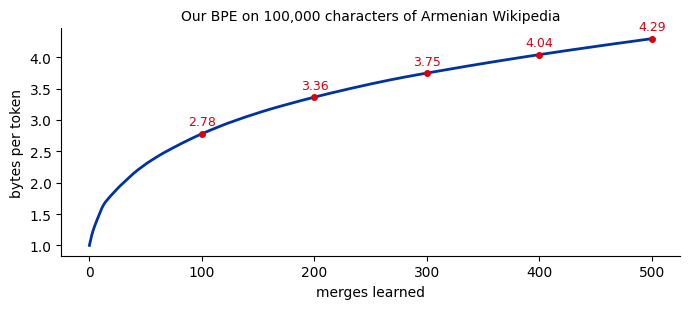

In [16]:
ks, bpt = zip(*curve)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(ks, bpt, color=BLUE, lw=2)
for k in (100, 200, 300, 400, 500):
    ax.annotate(f"{bpt[k]:.2f}", (k, bpt[k]), textcoords="offset points", xytext=(0, 6), ha="center",
                fontsize=9, color=RED)
    ax.plot(k, bpt[k], "o", color=RED, ms=4)
ax.set_xlabel("merges learned")
ax.set_ylabel("bytes per token")
ax.set_title("Our BPE on 100,000 characters of Armenian Wikipedia", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
R["bpe"]["bytes_per_token"] = {k: round(bpt[k], 2) for k in (100, 200, 300, 400, 500)}

Every merge helps less than the one before: the first 100 merges take the text from 1 to
about 2.8 bytes per token, the last 100 add a quarter of a byte. The frequent pairs go first; what is
left are rarer and rarer pairs.

## 1.7 The longest tokens

In [17]:
longest = sorted(merges.values(), key=lambda i: len(vocab[i]), reverse=True)[:10]
for i in longest:
    print(f"{len(vocab[i]):>3} bytes  {show(vocab[i])!r}")

 22 bytes  'ությունները'
 20 bytes  'ություններ'
 20 bytes  'յուղատնտես'
 20 bytes  '։\n\nՀայաստան'
 19 bytes  ' թվականին �'
 19 bytes  '։ Հայաստան'
 19 bytes  'կական լեռն'
 17 bytes  ' Հայաստան'
 17 bytes  '�այաստանը'
 17 bytes  ' թվականին'


Real words and endings (ություններ, Հայաստան), but also tokens that run straight across a sentence
end, with the full stop ։ and two line breaks inside one token. Our BPE has no idea where words end:
it merges whatever is frequent.

GPT's tokenizers avoid this. Before any merge, they cut the text with a regular expression, and merges
never cross a cut (LLM-1, "the regex"). Here is GPT-4o's cut on the same piece of text:

In [18]:
o200k = tiktoken.get_encoding("o200k_base")
print(regex.findall(o200k._pat_str, "։\n\nՀայաստանը"))

['։\n\n', 'Հայաստանը']


## 1.8 Use it

Encoding new text replays the learned merges, earliest first (the same loop as `minbpe`).

**Predict:** ours has 756 tokens, GPT-4o's has 200,000. How many tokens does each spend on LLM-1's line?

In [19]:
def encode(text):
    ids = list(text.encode("utf-8"))
    while len(ids) >= 2:
        stats = get_stats(ids)
        pair = min(stats, key=lambda p: merges.get(p, float("inf")))   # the earliest merge present
        if pair not in merges:
            break
        ids = merge(ids, pair, merges[pair])
    return ids


ours = encode(LINE)
print(f"ours (756 tokens):       {len(ours)} tokens")
print(f"GPT-4 (100,000 tokens):  {len(gpt4.encode(LINE))} tokens")
print(f"GPT-4o (200,000 tokens): {len(o200k.encode(LINE))} tokens")
print("our pieces:", [show(vocab[i]) for i in ours])
print("decodes back to the line:", decode(ours) == LINE)
R["bpe"]["line_tokens"] = {"ours": len(ours), "gpt4": len(gpt4.encode(LINE)), "gpt4o": len(o200k.encode(LINE))}

ours (756 tokens):       28 tokens
GPT-4 (100,000 tokens):  102 tokens
GPT-4o (200,000 tokens): 19 tokens
our pieces: ['�', '�', 'ս', ' այ', 'ս', ' ամ', 'են', 'ին �', '�', 'այ', 'ում ե', 'մ', ' լ', 'ու�', '�', ', և', ' գ', 'իտ', 'ակ', 'ներ', ' են �', '�', 'ոս', 'ում �', '�', 'մ', ' մ', 'եջ']
decodes back to the line: True


Under a minute of training on 100,000 characters beat GPT-4's tokenizer on Armenian by a factor of
almost four. Vocabulary size is not what matters; what matters is **how much Armenian the tokenizer
saw** while it learned its merges. GPT-4o's saw a lot more than ours: it wins.

## 1.9 Now we pay the tax

**Predict:** how well does our tokenizer do on English?

In [20]:
# ~15-30 s
held_out = "\n\n".join(hy_articles)[200_000:230_000]      # Armenian it never saw in training
english = "\n\n".join(en_articles)[:30_000]
for name, text in [("Armenian (unseen)", held_out), ("English", english)]:
    n = len(encode(text))
    print(f"{name:18s} {len(text):,} characters -> {n:,} tokens: {len(text) / n:.2f} characters per token")
    R["bpe"][f"chars_per_token_{name.split()[0].lower()}"] = round(len(text) / n, 2)

Armenian (unseen)  30,000 characters -> 14,677 tokens: 2.04 characters per token


English            30,000 characters -> 29,468 tokens: 1.02 characters per token


About one character per token in English: our tokenizer never saw an English letter pair, so English
is spelled out almost byte by byte. That is GPT-4's tokenizer on Armenian, mirrored.

> **Remember:** BPE learns the merges of the text it is trained on. A language that is rare in that
> text stays in small pieces, however big the vocabulary.

# Part 2 - Audit the pros

Fourteen tokenizers, all public: OpenAI's through `tiktoken`, the rest as `tokenizer.json` files from
Hugging Face (Llama 3, Llama 4 and Gemma 2 from community mirrors, since their makers' own
repositories need an approved request). Same Armenian text through all of them.

In [21]:
LINEUP = [  # label, kind, source
    ("mBERT (2018)",       "hf", "google-bert/bert-base-multilingual-cased"),
    ("XLM-R (2019)",       "hf", "FacebookAI/xlm-roberta-base"),
    ("GPT-2 (2019)",       "tt", "gpt2"),
    ("GPT-4 (2023)",       "tt", "cl100k_base"),
    ("GPT-4o (2024)",      "tt", "o200k_base"),
    ("Llama 3 (2024)",     "hf", "Xenova/llama3-tokenizer"),
    ("Gemma 2 (2024)",     "hf", "unsloth/gemma-2-9b"),
    ("Qwen 2.5 (2024)",    "hf", "Qwen/Qwen2.5-7B"),
    ("DeepSeek-V3 (2024)", "hf", "deepseek-ai/DeepSeek-V3"),
    ("Llama 4 (2025)",     "hf", "unsloth/Llama-4-Scout-17B-16E-Instruct"),
    ("Qwen3 (2025)",       "hf", "Qwen/Qwen3-0.6B"),
    ("gpt-oss (2025)",     "tt", "o200k_harmony"),
    ("Qwen3.5 (2026)",     "hf", "Qwen/Qwen3.5-2B"),
    ("Gemma 4 (2026)",     "hf", "google/gemma-4-E2B-it"),
]


def load(kind, src):
    if kind == "tt":
        return tiktoken.get_encoding(src)
    return Tokenizer.from_file(hf_hub_download(src, "tokenizer.json"))


def encode_many(tok, kind, texts):
    if kind == "tt":
        return tok.encode_batch(texts, disallowed_special=())
    return [e.ids for e in tok.encode_batch(texts, add_special_tokens=False)]


def vocab_strings(tok, kind):
    # every token as text; half-letter bytes show as the replacement mark
    if kind == "tt":
        out = {}
        for i in range(tok.n_vocab):
            try:
                out[i] = tok.decode_single_token_bytes(i).decode("utf-8", errors="replace")
            except KeyError:                              # gaps in the table
                pass
        return out
    ids = list(range(tok.get_vocab_size()))
    return dict(zip(ids, tok.decode_batch([[i] for i in ids], skip_special_tokens=False)))

Where each tokenizer learned its **first Armenian merge** tells us how much Armenian its training text
had: BPE learns merges in order of frequency, so an early Armenian merge means Armenian was common.
OpenAI's tables list the merges as ranks; the others list them in `tokenizer.json`, written in GPT-2's
byte alphabet (each byte shown as a printable character), which we translate back.

In [22]:
def gpt2_byte_alphabet():
    # GPT-2's printable stand-in for each of the 256 bytes, inverted: stand-in char -> byte
    bs = list(range(33, 127)) + list(range(161, 173)) + list(range(174, 256))
    cs, n = bs[:], 0
    for b in range(256):
        if b not in bs:
            bs.append(b)
            cs.append(256 + n)
            n += 1
    return {chr(c): b for b, c in zip(bs, cs)}


BYTE_OF = gpt2_byte_alphabet()


def first_armenian_merge(kind, tok, src):
    # (rank of the first merge that makes Armenian text, number of merges), or None if no merge list
    if kind == "tt":
        ranked = sorted(tok._mergeable_ranks.items(), key=lambda kv: kv[1])
        assert all(len(b) == 1 for b, _ in ranked[:256]), "ranks 0-255 should be the single bytes"
        n = len(ranked) - 256                       # ranks 0-255 are the bytes themselves
        for b, rank in ranked:
            if ARMENIAN.search(b.decode("utf-8", errors="ignore")):
                return rank - 256, n
        return None, n
    model = json.loads(Path(hf_hub_download(src, "tokenizer.json")).read_text(encoding="utf-8"))["model"]
    if "merges" not in model:                       # WordPiece (mBERT) and Unigram (XLM-R) have none
        return None
    for rank, m in enumerate(model["merges"]):
        a, b = m if isinstance(m, list) else m.split(" ", 1)
        if all(ch in BYTE_OF for ch in a + b):      # byte-level: translate back to bytes
            text = bytes(BYTE_OF[ch] for ch in a + b).decode("utf-8", errors="ignore")
        else:                                       # SentencePiece-style pieces are plain text
            text = a + b
        if ARMENIAN.search(text):
            return rank, len(model["merges"])
    return None, len(model["merges"])

## 2.1 Fourteen tokenizers, five measurements

For each tokenizer we measure:

- its **Armenian tokens**: vocabulary entries with at least one Armenian letter;
- LLM-1's **line** and its English gloss, in tokens;
- the **Armenian premium**: tokens for the 1,997 Armenian NTREX sentences divided by tokens for the
  same 1,997 sentences in English. Same meaning, so x2 means Armenian costs twice as much;
- **characters per token** on 2 million characters of Armenian Wikipedia: how much text one token
  carries;
- the share of the 20,000 most common Armenian words that cost **more tokens than letters**.

In [23]:
# ~2-4 min: 14 tokenizers, one at a time (the first run also downloads ~120 MB of tokenizer files)
hy_2m, total = [], 0
for a in hy_articles:
    hy_2m.append(a)
    total += len(a)
    if total >= 2_000_000:
        break
WORD = re.compile(r"[Ա-Ֆա-և]+")
words = [w for w, _ in Counter(WORD.findall("\n".join(hy_2m))).most_common(20_000)]
hy_chars = sum(map(len, hy_2m))


def n_tokens(tok, kind, texts, batch=100):
    return sum(len(x) for i in range(0, len(texts), batch) for x in encode_many(tok, kind, texts[i:i + batch]))


audit, t0 = {}, time.time()
for k, (label, kind, src) in enumerate(LINEUP, 1):
    tok = load(kind, src)
    strings = vocab_strings(tok, kind)
    arm_ids = [i for i, s in strings.items() if ARMENIAN.search(s)]
    word_lens = [len(x) for i in range(0, len(words), 5000) for x in encode_many(tok, kind, words[i:i + 5000])]
    audit[label] = {
        "vocab": len(strings), "armenian_tokens": len(arm_ids),
        "armenian_set": {strings[i] for i in arm_ids},          # as text, to compare two vocabularies
        "line": len(encode_many(tok, kind, [LINE])[0]), "gloss": len(encode_many(tok, kind, [GLOSS])[0]),
        "premium": n_tokens(tok, kind, par_hy) / n_tokens(tok, kind, par_en),
        "hy_chars_per_token": hy_chars / n_tokens(tok, kind, hy_2m),
        "pct_words_exploding": 100 * sum(n > len(w) for w, n in zip(words, word_lens)) / len(words),
        "first_merge": first_armenian_merge(kind, tok, src),
    }
    del tok, strings
    el = time.time() - t0
    print(f"{k:>2}/{len(LINEUP)} {label:20s} premium x{audit[label]['premium']:.2f}   "
          f"{el:.0f} s, ~{el / k * (len(LINEUP) - k):.0f} s left")

 1/14 mBERT (2018)         premium x1.98   10 s, ~128 s left


 2/14 XLM-R (2019)         premium x1.32   25 s, ~151 s left


 3/14 GPT-2 (2019)         premium x9.18   35 s, ~127 s left


 4/14 GPT-4 (2023)         premium x9.16   44 s, ~110 s left


 5/14 GPT-4o (2024)        premium x1.73   64 s, ~115 s left


...

10/14 Llama 4 (2025)       premium x4.47   163 s, ~65 s left


11/14 Qwen3 (2025)         premium x4.93   184 s, ~50 s left


12/14 gpt-oss (2025)       premium x1.73   191 s, ~32 s left


13/14 Qwen3.5 (2026)       premium x3.49   211 s, ~16 s left


14/14 Gemma 4 (2026)       premium x2.70   233 s, ~0 s left


**Predict:** which of the 14 is the cheapest for Armenian? Which the most expensive?

In [24]:
table = pd.DataFrame({
    "vocabulary": {l: a["vocab"] for l, a in audit.items()},
    "Armenian tokens": {l: a["armenian_tokens"] for l, a in audit.items()},
    "line (Armenian)": {l: a["line"] for l, a in audit.items()},
    "gloss (English)": {l: a["gloss"] for l, a in audit.items()},
    "Armenian premium": {l: round(a["premium"], 2) for l, a in audit.items()},
    "chars per token (hy Wikipedia)": {l: round(a["hy_chars_per_token"], 2) for l, a in audit.items()},
}).sort_values("Armenian premium")
R["audit"] = table.to_dict(orient="index")
table

,vocabulary,Armenian tokens,line (Armenian),gloss (English),Armenian premium,chars per token (hy Wikipedia)
XLM-R (2019),250002,3528,17,18,1.32,3.36
GPT-4o (2024),200000,1753,19,17,1.73,2.92
gpt-oss (2025),201088,1753,19,17,1.73,2.92
mBERT (2018),119547,1236,24,18,1.98,2.50
Gemma 4 (2026),262144,250,30,16,2.70,1.89
Gemma 2 (2024),256000,246,31,16,2.85,1.82
DeepSeek-V3 (2024),128815,205,32,18,2.86,1.86
Qwen3.5 (2026),248070,88,38,17,3.49,1.48
Llama 4 (2025),201135,34,51,17,4.47,1.18
Qwen 2.5 (2024),151665,79,57,18,4.93,1.03


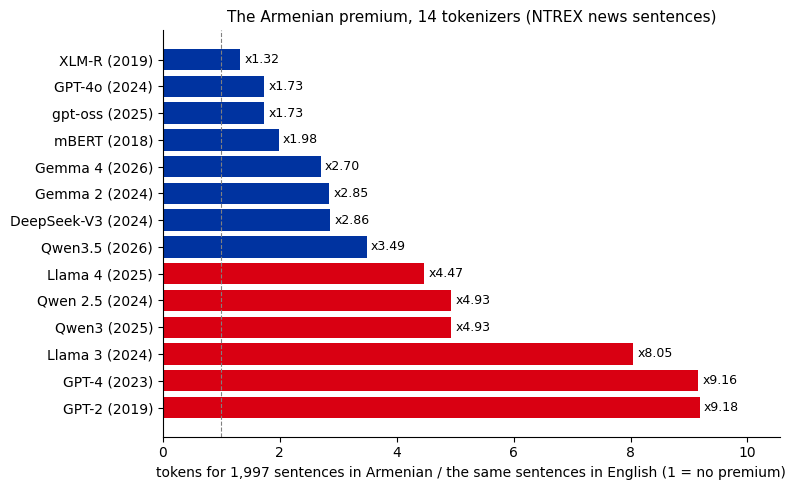

In [25]:
order = table.index[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(order, table.loc[order, "Armenian premium"],
               color=[RED if table.loc[l, "Armenian premium"] > 4 else BLUE for l in order])
ax.bar_label(bars, labels=[f"x{v:.2f}" for v in table.loc[order, "Armenian premium"]], padding=3, fontsize=9)
ax.axvline(1, color="gray", lw=0.8, ls="--")
ax.set_xlim(0, table["Armenian premium"].max() * 1.15)
ax.set_xlabel("tokens for 1,997 sentences in Armenian / the same sentences in English (1 = no premium)")
ax.set_title("The Armenian premium, 14 tokenizers (NTREX news sentences)", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

- **Cheapest: XLM-R (2019)**, at x1.32, built for 100 languages. Then GPT-4o and gpt-oss at x1.73 and
  mBERT (2018) at x1.98. The two oldest multilingual tokenizers (2018-2019) are among the best for
  Armenian; GPT-2, from the same year as XLM-R, is the worst.
- **Most expensive: GPT-2 and GPT-4**, about x9.2: no Armenian tokens at all, so every letter costs two
  byte tokens. Llama 3 (x8.05) has exactly two Armenian tokens.
- **The 2025-2026 tokenizers sit in the middle:** Gemma 4 x2.70, Qwen3.5 x3.49, Llama 4 x4.47.
- **Size is not the answer.** Gemma 4 has the biggest vocabulary of all (262,144) and charges x2.70;
  GPT-4o's 200,000 charge x1.73.

The line and the gloss tell a gentler story (GPT-4o: 19 against 17 tokens). One short line of poetry
is a noisy measure; 1,997 sentences are not. The last column says the same thing from the other side:
GPT-4's tokenizer carries 0.56 characters of Armenian Wikipedia per token, fewer than one letter.

## 2.2 New model, same tokenizer?

A new model does not always get a new tokenizer. Two pairs in the line-up look suspiciously alike.
Compare their Armenian tokens directly:

In [26]:
for a, b in [("GPT-4o (2024)", "gpt-oss (2025)"), ("Qwen 2.5 (2024)", "Qwen3 (2025)"),
             ("Qwen3 (2025)", "Qwen3.5 (2026)"), ("Llama 3 (2024)", "Llama 4 (2025)"),
             ("Gemma 2 (2024)", "Gemma 4 (2026)")]:
    sa, sb = audit[a]["armenian_set"], audit[b]["armenian_set"]
    same = "identical" if sa == sb else f"{len(sa & sb)} shared, {len(sb - sa)} new in {b}"
    print(f"{a:16s} -> {b:15s} Armenian tokens {len(sa):>5,} -> {len(sb):>5,}   ({same}),  "
          f"premium x{audit[a]['premium']:.2f} -> x{audit[b]['premium']:.2f}")

GPT-4o (2024)    -> gpt-oss (2025)  Armenian tokens 1,753 -> 1,753   (identical),  premium x1.73 -> x1.73
Qwen 2.5 (2024)  -> Qwen3 (2025)    Armenian tokens    79 ->    79   (identical),  premium x4.93 -> x4.93
Qwen3 (2025)     -> Qwen3.5 (2026)  Armenian tokens    79 ->    88   (36 shared, 52 new in Qwen3.5 (2026)),  premium x4.93 -> x3.49
Llama 3 (2024)   -> Llama 4 (2025)  Armenian tokens     2 ->    34   (2 shared, 32 new in Llama 4 (2025)),  premium x8.05 -> x4.47
Gemma 2 (2024)   -> Gemma 4 (2026)  Armenian tokens   246 ->   250   (196 shared, 54 new in Gemma 4 (2026)),  premium x2.85 -> x2.70


Two "new" tokenizers are old ones: **gpt-oss (2025) reuses GPT-4o's vocabulary**, and **Qwen3 (2025)
reuses Qwen 2.5's**. Their Armenian tokens are identical, and the vocabularies differ only by a few
special tokens for the chat format (201,088 against 200,000; 151,669 against 151,665). Changing a tokenizer means every embedding row has to be learned
again (LLM-1's last slide), so a new model often keeps the old one.

When the vocabulary does change, Armenian improves, but slowly: Llama 3 to Llama 4 goes from 2 to
34 Armenian tokens and from x8.05 to x4.47; Qwen3.5 swaps in 52 new Armenian tokens (dropping 43 of
Qwen3's) and goes to x3.49; Gemma 4
swaps out about 50 of Gemma 2's and barely moves.

## 2.3 Merge archaeology

How far into its merge list does each tokenizer learn its first Armenian merge? Early means Armenian
was common in its training text; late means it barely made the cut. (mBERT and XLM-R are not BPE and
have no merge list.)

In [27]:
arch = {l: a["first_merge"] for l, a in audit.items() if a["first_merge"] and a["first_merge"][0] is not None}
arch = dict(sorted(arch.items(), key=lambda kv: kv[1][0] / kv[1][1]))
for l, (rank, n) in arch.items():
    print(f"{l:20s} merge {rank:>7,} of {n:>7,}  ({100 * rank / n:5.1f}% of the way through)")
no_merge = [l for l, a in audit.items() if a["first_merge"] and a["first_merge"][0] is None]
print("no Armenian merge at all:", no_merge)
R["first_armenian_merge"] = {l: {"rank": r, "of": n} for l, (r, n) in arch.items()}

GPT-4o (2024)        merge     363 of 199,742  (  0.2% of the way through)
gpt-oss (2025)       merge     363 of 199,742  (  0.2% of the way through)
DeepSeek-V3 (2024)   merge   2,933 of 127,741  (  2.3% of the way through)
Gemma 2 (2024)       merge  40,020 of 580,604  (  6.9% of the way through)
Gemma 4 (2026)       merge  36,558 of 514,906  (  7.1% of the way through)
Llama 4 (2025)       merge  55,504 of 439,802  ( 12.6% of the way through)
Qwen3.5 (2026)       merge 148,759 of 247,587  ( 60.1% of the way through)
Llama 3 (2024)       merge 263,556 of 280,147  ( 94.1% of the way through)
Qwen 2.5 (2024)      merge 144,669 of 151,387  ( 95.6% of the way through)
Qwen3 (2025)         merge 144,669 of 151,387  ( 95.6% of the way through)
no Armenian merge at all: ['GPT-2 (2019)', 'GPT-4 (2023)']


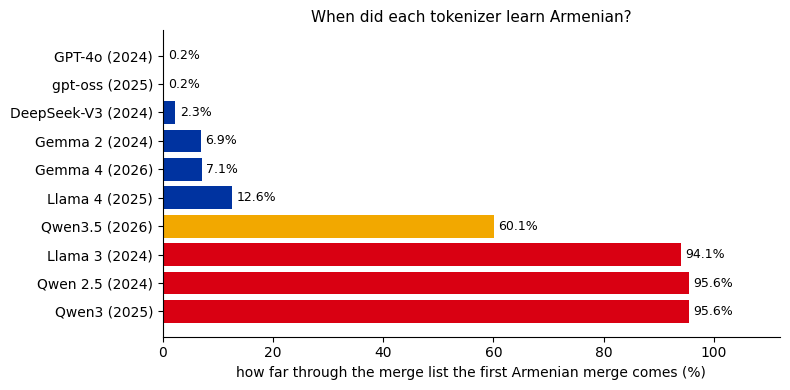

In [28]:
labels = list(arch)[::-1]
pct = [100 * arch[l][0] / arch[l][1] for l in labels]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(labels, pct, color=[BLUE if p < 20 else ORANGE if p < 80 else RED for p in pct])
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in pct], padding=3, fontsize=9)
ax.set_xlim(0, 112)
ax.set_xlabel("how far through the merge list the first Armenian merge comes (%)")
ax.set_title("When did each tokenizer learn Armenian?", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

GPT-4o's tokenizer learns its first Armenian merge as merge number 363 of almost 200,000: Armenian was
common enough in its training text to earn a merge almost at once. DeepSeek-V3 gets there 2% of the way
in, the Gemmas at 7%, Llama 4 at 13%, Qwen3.5 at 60%. Llama 3 and Qwen 2.5 / Qwen3 wait until 94-96% of the way
through - Armenian barely made their cut - and GPT-2 and GPT-4 never merge two Armenian bytes at all.

## 2.4 Words that cost more tokens than letters

Of the 20,000 most common Armenian words, how many cost more tokens than they have letters?

In [29]:
explode = pd.Series({l: round(a["pct_words_exploding"], 1) for l, a in audit.items()},
                    name="% of words with more tokens than letters").sort_values(ascending=False)
R["pct_words_exploding"] = explode.to_dict()
explode.to_frame()

,% of words with more tokens than letters
GPT-2 (2019),100.0
GPT-4 (2023),100.0
Llama 3 (2024),99.9
Llama 4 (2025),27.6
Qwen3.5 (2026),5.0
DeepSeek-V3 (2024),2.1
Qwen 2.5 (2024),1.3
Qwen3 (2025),1.3
XLM-R (2019),0.1
GPT-4o (2024),0.1


Under GPT-2 and GPT-4, every one of the 20,000 most common Armenian words costs more tokens than it
has letters; under Llama 3, all but about twenty. Llama 4 brings that down to about a quarter of the
words, and for the rest it is 5% or less.

> **Remember:** the vocabulary sets the price of a language - in money per call and in how much fits
> in the context - and a new model often keeps its old vocabulary.

# Part 3 - Hunt a glitch

LLM-1 met ` SolidGoldMagikarp`: a token in GPT-2's vocabulary that almost never appeared in the text
the model was trained on, so the model never learned what to do with it. LLM-2 showed why: a row of the
embedding table gets a gradient only when its token shows up.

## 3.1 Tokens that never come out

The recipe for finding such tokens needs no model at all: tokenize a large amount of real text and
look for vocabulary entries that **never come out**. We do it for GPT-4o's 200,000 tokens and 20
million characters of Armenian Wikipedia.

In [30]:
# ~5-15 s
hy_counts = Counter()
for i in range(0, len(hy_articles), 200):
    for ids in o200k.encode_batch(hy_articles[i:i + 200], disallowed_special=()):
        hy_counts.update(ids)
o200k_armenian = {}
for i in range(o200k.n_vocab):
    try:
        s = o200k.decode_single_token_bytes(i).decode("utf-8", errors="replace")
    except KeyError:
        continue
    if ARMENIAN.search(s):
        o200k_armenian[i] = s
print(f"GPT-4o's tokenizer has {len(o200k_armenian):,} Armenian tokens; "
      f"{sum(hy_counts[i] for i in o200k_armenian):,} of them come out of the 20M characters")

GPT-4o's tokenizer has 1,753 Armenian tokens; 5,998,374 of them come out of the 20M characters


**Predict:** of those Armenian tokens, how many never appear even once in 20 million characters of
Armenian Wikipedia?

In [31]:
never = [i for i in o200k_armenian if hy_counts[i] == 0]
rarest = sorted(o200k_armenian, key=lambda i: hy_counts[i])[:12]
print(f"never seen: {len(never)}: {[o200k_armenian[i] for i in never]}")
print("the rarest:", [(o200k_armenian[i], hy_counts[i]) for i in rarest])
R["o200k"] = {"armenian_tokens": len(o200k_armenian), "never_seen": [o200k_armenian[i] for i in never],
              "rarest": [(o200k_armenian[i], hy_counts[i]) for i in rarest]}

never seen: 2: ['աեւ', ' վերաբերյ']
the rarest: [('աեւ', 0), (' վերաբերյ', 0), (' որովհ', 2), (' հետեւ', 2), (' որտ', 4), (' նաեւ', 7), ('եւոր', 7), (' հաղ', 9), ('րբե�', 10), (' Դուք', 10), (' ուզ', 14), (' Ձեր', 14)]


Two never come out: "աեւ" and " վերաբերյ". A few more come out fewer than ten times: " որովհ" and
" հետեւ" twice each, " նաեւ" seven times. Why would a tokenizer keep tokens that 20 million characters
of Armenian almost never produce? Two reasons.

### Reason 1: swallowed by a longer token

BPE merges step by step, so every long token has shorter tokens on the way to it. If the long token
always wins, the step before it never survives to the end of tokenization:

In [32]:
def pieces(enc, text):
    return [enc.decode_single_token_bytes(i).decode("utf-8", errors="replace") for i in enc.encode(text)]


for text in [" վերաբերյալ", " վերաբերյալ է", " վերաբերյան"]:
    print(f"{text!r:16} -> {pieces(o200k, text)}")

' վերաբերյալ'    -> [' վերաբերյալ']
' վերաբերյալ է'  -> [' վերաբերյալ', ' է']
' վերաբերյան'    -> [' վերաբերյ', 'ան']


" վերաբերյ" is a step on the way to " վերաբերյալ" ("regarding"), which is a token of its own. In real
text the whole word wins, so the step survives only when the word ends differently, as in the odd form
" վերաբերյան". The tokenizer keeps a token that its own longer merge almost always swallows.

### Reason 2: a different spelling

Armenian has two spellings. The reformed one, used in Armenia and on Armenian Wikipedia, writes the
word "and" as **և**; the classical one, used by Western Armenian and much of the diaspora, writes
**եւ**. Which one did Wikipedia use, and which one did GPT-4o's tokenizer learn?

In [33]:
wiki = "".join(hy_articles)
n_yev, n_ew = wiki.count("և"), wiki.count("եւ")
del wiki
print(f"Armenian Wikipedia: 'և' {n_yev:,} times, 'եւ' {n_ew:,} times")
ew_tokens = sorted({s for s in o200k_armenian.values() if "եւ" in s})
yev_tokens = sorted({s for s in o200k_armenian.values() if "և" in s})
print(f"GPT-4o's tokens with 'եւ': {len(ew_tokens)} {ew_tokens}")
print(f"GPT-4o's tokens with 'և':  {len(yev_tokens)}")
for text in [" որովհետև", " որովհետեւ"]:
    print(f"{text!r:13} -> {pieces(o200k, text)}")
R["spelling"] = {"wiki_yev": n_yev, "wiki_ew": n_ew, "o200k_ew_tokens": ew_tokens,
                 "o200k_yev_tokens": len(yev_tokens)}

Armenian Wikipedia: 'և' 127,294 times, 'եւ' 404 times
GPT-4o's tokens with 'եւ': 6 [' եւ', ' հետեւ', ' նաեւ', 'աեւ', 'եւ', 'եւոր']
GPT-4o's tokens with 'և':  20
' որովհետև'   -> [' որովհետև']
' որովհետեւ'  -> [' որովհ', 'ետ', 'եւ']


Wikipedia writes **և** 127,294 times and **եւ** only 404. GPT-4o's tokenizer has 20 tokens with և,
but also 6 with եւ (" նաեւ", " հետեւ", "աեւ", ...): part of the text it was trained on used the classical
spelling. That is where " որովհ" comes from. It is the start of որովհետեւ, "because" in the classical
spelling; the reformed որովհետև is a single token of its own, so in Wikipedia " որովհ" has nothing to
attach to.

### The newer tokenizers

Do the 2024-2026 tokenizers from Part 2 have such tokens too?

In [34]:
# ~2-5 min: four tokenizers over 20M characters each
for label in ["DeepSeek-V3 (2024)", "Llama 4 (2025)", "Qwen3.5 (2026)", "Gemma 4 (2026)"]:
    _, kind, src = next(x for x in LINEUP if x[0] == label)
    tok = load(kind, src)
    arm = {i: s for i, s in vocab_strings(tok, kind).items() if ARMENIAN.search(s)}
    counts_here = Counter()
    for i in range(0, len(hy_articles), 200):
        for ids in encode_many(tok, kind, hy_articles[i:i + 200]):
            counts_here.update(ids)
    rare = sorted(arm, key=lambda i: counts_here[i])[:5]
    n_never = sum(counts_here[i] == 0 for i in arm)
    print(f"{label:20s} {len(arm):>4} Armenian tokens, never seen: {n_never};  "
          f"rarest: {[(arm[i].strip(), counts_here[i]) for i in rare]}")
    R.setdefault("newer_never_seen", {})[label] = n_never
    del tok, arm, counts_here

DeepSeek-V3 (2024)    205 Armenian tokens, never seen: 0;  rarest: [('բառարան', 222), ('Երև', 975), ('բառ', 1764), ('թվ', 2823), ('Երևան', 3907)]


Llama 4 (2025)         34 Armenian tokens, never seen: 0;  rarest: [('ւ', 44485), ('են', 68652), ('ու�', 101979), ('ել', 113791), ('ութ', 136565)]


Qwen3.5 (2026)         88 Armenian tokens, never seen: 0;  rarest: [('է', 4906), ('ութ', 7165), ('ությ', 8549), ('Հ', 13676), ('Ա', 16537)]


Gemma 4 (2026)        250 Armenian tokens, never seen: 0;  rarest: [('՜', 98), ('եւ', 172), ('Ր', 308), ('՞', 448), ('Ւ', 498)]


None of the four has a single never-seen Armenian token. Their rarest ones are capital letters,
punctuation and short pieces that still come out about a hundred times or more. They own far fewer
Armenian tokens (34 to 250, against GPT-4o's 1,753), and each of those earns its place. Fewer Armenian
tokens means fewer glitches, and a higher price (Part 2).

## 3.2 Can the models say them?

Three OpenAI models share GPT-4o's vocabulary: **gpt-4o-mini** (2024), **gpt-4.1-nano** (2025) and
the open **gpt-oss-20b** (2025, which thinks before it answers). We ask each to repeat, and to spell,
four rare tokens and three controls, at temperature 0.

One detail decides everything. A glitch token reaches the model only if the prompt really contains
it. After "...: " the word starts with a space, and " վերաբերյ" is **one** token. Inside quotes it
starts without a space, and then it is not:

In [35]:
WORDS = ["վերաբերյ", "որովհ", "հետեւ", "նաեւ",                # rare: 0, 2, 2 and 7 times in 20M characters
         "Հայաստան", "վերաբերյալ", "որովհետև"]                 # controls: common words
PROMPTS = {
    "repeat": "Repeat the following string exactly, output nothing else: {w}",
    "repeat_quoted": 'Repeat the string between the quotes exactly, output nothing else: "{w}"',
    "spell": "Spell the following Armenian word letter by letter, separated by spaces, "
             "output only the letters: {w}",
}
w = "վերաբերյ"
for task in ("repeat", "repeat_quoted"):
    ids = o200k.encode(PROMPTS[task].format(w=w))
    print(f"{task:14s} ends with {[o200k.decode_single_token_bytes(i).decode('utf-8', 'replace') for i in ids[-5:]]}")

repeat         ends with [' output', ' nothing', ' else', ':', ' վերաբերյ']
repeat_quoted  ends with ['վ', 'եր', 'աբ', 'երյ', '"']


So "repeat" hands the model the rare token; "repeat_quoted" hands it the same letters as four common
tokens. If the model fails the first and passes the second, the problem is the **token**, not the word.

The calls go through OpenRouter. Every call is written to `results/02_probe_ledger.json` with its
token usage and cost.

In [36]:
API = "https://openrouter.ai/api/v1"
MODELS = {"openai/gpt-4o-mini": False, "openai/gpt-4.1-nano": False, "openai/gpt-oss-20b": True}   # thinks?


def api_key():
    for line in Path("../../.env").read_text(encoding="utf-8").splitlines():
        if line.startswith("OPENROUTER_API_KEY="):
            return line.split("=", 1)[1].strip()
    raise RuntimeError("OPENROUTER_API_KEY is not in the repository's .env file")


session = requests.Session()
session.headers["Authorization"] = f"Bearer {api_key()}"
served = {m["id"]: m["pricing"] for m in session.get(f"{API}/models", timeout=60).json()["data"]}
price = {m: (float(served[m]["prompt"]), float(served[m]["completion"])) for m in MODELS}   # KeyError = not served
print({m: f"${p[0] * 1e6:.3f} / ${p[1] * 1e6:.3f} per million tokens in / out" for m, p in price.items()})


def ask(model, prompt):
    thinks = MODELS[model]
    body = {"model": model, "messages": [{"role": "user", "content": prompt}], "temperature": 0,
            "max_tokens": 3000 if thinks else 80, "usage": {"include": True}}
    if thinks:
        body["reasoning"] = {"effort": "low"}
    reply = session.post(f"{API}/chat/completions", json=body, timeout=300)
    reply.raise_for_status()
    j = reply.json()
    if "choices" not in j:
        raise RuntimeError(f"{model}: unexpected reply {j}")
    msg = j["choices"][0]["message"]
    usage = j.get("usage")          # missing when the model replies with nothing at all - a glitch symptom
    cost = (usage["prompt_tokens"] * price[model][0] + usage["completion_tokens"] * price[model][1]
            if usage else None)
    return {"answer": (msg.get("content") or "").strip(), "reasoning": msg.get("reasoning") or "",
            "finish": j["choices"][0].get("finish_reason"), "usage": usage, "cost": cost}


def credits_used():
    # the account's running total in dollars: the honest measure of what the probe cost
    return session.get(f"{API}/credits", timeout=60).json()["data"]["total_usage"]

{'openai/gpt-4o-mini': '$0.150 / $0.600 per million tokens in / out', 'openai/gpt-4.1-nano': '$0.100 / $0.400 per million tokens in / out', 'openai/gpt-oss-20b': '$0.018 / $0.090 per million tokens in / out'}


In [37]:
# ~2 min, ~$0.0005: 3 models x 7 words x 3 tasks = 63 calls
ledger, t0, before = [], time.time(), credits_used()
jobs = [(m, w, t) for m in MODELS for w in WORDS for t in PROMPTS]
for k, (m, w, t) in enumerate(jobs, 1):
    r = ask(m, PROMPTS[t].format(w=w))
    ledger.append({"model": m, "word": w, "task": t, **r})
    tmp = RESULTS / "02_probe_ledger.json.tmp"           # write, then rename: a crash never eats the ledger
    tmp.write_text(json.dumps(ledger, ensure_ascii=False, indent=1), encoding="utf-8")
    tmp.replace(RESULTS / "02_probe_ledger.json")
    if k % 9 == 0 or k == len(jobs):
        el = time.time() - t0
        print(f"{k}/{len(jobs)} calls, {el:.0f} s, ~{el / k * (len(jobs) - k):.0f} s left")
time.sleep(10)                                           # the account total lags the calls by a few seconds
spent = credits_used() - before
no_usage = [(x["model"], x["word"], x["task"]) for x in ledger if x["usage"] is None]
truncated = [(x["model"], x["word"], x["task"]) for x in ledger if x["finish"] != "stop"]
print(f"spent: ${spent:.5f} (the account's total before and after); calls that reported no usage: "
      f"{len(no_usage)}")
print("answers cut off by the token limit (these say nothing about the token):", truncated)
R["probe"] = {"calls": len(ledger), "spent_usd": spent, "no_usage": no_usage, "truncated": truncated}

9/63 calls, 9 s, ~55 s left


18/63 calls, 17 s, ~41 s left


27/63 calls, 26 s, ~35 s left


36/63 calls, 36 s, ~27 s left


45/63 calls, 67 s, ~27 s left


54/63 calls, 77 s, ~13 s left


63/63 calls, 119 s, ~0 s left


spent: $0.00047 (the account's total before and after); calls that reported no usage: 2
answers cut off by the token limit (these say nothing about the token): []


The answers. An empty cell means the model replied with nothing at all.

In [38]:
probe = pd.DataFrame(ledger)
probe["answer"] = probe["answer"].str.slice(0, 30)
for m in MODELS:
    print(m)
    display(probe[probe.model == m].pivot(index="word", columns="task", values="answer").loc[WORDS])

openai/gpt-4o-mini


task,repeat,repeat_quoted,spell
word,,,
վերաբերյ,,վերաբերյ,Բ ե ր գ ւ ւ ւ
որովհ,,որովհ,ր ո գ ւ ւ
հետեւ,հետեւ,հետեւ,հ ե տ ե վ
նաեւ,նաեւ,նաեւ,ն ե ւ
Հայաստան,Հայաստան,Հայաստան,Հ յ ա ս տ ա ն
վերաբերյալ,վերաբերյալ,վերաբերյալ,վ ե ր բ ե ր ա լ
որովհետև,վերցրել,"""որովհետև""",վ ո ր ո ւ թ և


openai/gpt-4.1-nano


task,repeat,repeat_quoted,spell
word,,,
վերաբերյ,挂牌,վերաբերյ,շ ա յ դ ա յ ր
որովհ,پور,որովհ,I believe there might be a mis
հետեւ,հետեւ,հետեւ,յ ե վ կ ե թ ւ
նաեւ,եւայն,նաեւ,ո ւ ւ յ
Հայաստան,Հայաստան,Հայաստան,Հ ա ն գ ս տ ա ն
վերաբերյալ,բնութաբյլ,վերաբերյալ,բ ո լ ե բ ա հ յ լ
որովհետև,Because,որովհետև,վ ի ն ա յ ն ե


openai/gpt-oss-20b


task,repeat,repeat_quoted,spell
word,,,
վերաբերյ,բ,վերաբերյ,բ ր յ
որովհ,<|channel|>,որովհ,հ ա վ ո
հետեւ,հետեւ,հետեւ,հ ե տ ե վ
նաեւ,,նայել,Ն ա և
Հայաստան,Հայաստան,Հայաստան,Հ ա յ ա ս տ ա ն
վերաբերյալ,վերաբերող,վերաբերյալ,վ ե ռ ա բ ե ր ա կ ան
որովհետև,որովհետև,որովհետև,վ о р о թ е վ ը


What the saved run (28 October 2026) shows; at temperature 0 the details still change from run to run,
so read your own tables against this:

- **The two never-seen tokens (first two rows).** Asked to repeat them bare, gpt-4o-mini replies with
  nothing at all (these are the two calls that reported no usage), gpt-4.1-nano answers in other
  scripts (Chinese 挂牌, Persian پور), and gpt-oss-20b gives a single letter or one of its own control
  tokens, `<|channel|>`. Quoted - the same letters as ordinary tokens - all three repeat them exactly.
  The problem is the **token**, not the word.
- **The rare ones.** հետեւ comes through everywhere, but նաեւ breaks for gpt-4.1-nano (it writes
  եւայն) and for gpt-oss-20b (it replies with nothing). Rare in Wikipedia is not always rare in
  the text a model was trained on.
- **Even common words are not safe.** gpt-4o-mini replaces որովհետև with another word, վերցրել
  ("took"); gpt-4.1-nano translates it into "Because" and garbles վերաբերյալ.
- **Spelling fails almost everywhere**, controls included: the models see tokens, not letters (LLM-1's
  strawberry problem). gpt-oss-20b even slips three Cyrillic letters, о, р and е, into its spelling of
  որովհետև: they look like Armenian letters and are not.

gpt-oss-20b thinks before it answers, and its thinking is returned to us. What did it think when asked
to spell the first word?

In [39]:
x = next(x for x in ledger if x["model"] == "openai/gpt-oss-20b" and x["word"] == "վերաբերյ" and x["task"] == "spell")
print(f"answer: {x['answer']!r}   ({x['usage']['completion_tokens']} tokens written)")
print("thinking, first 400 characters:")
print(x["reasoning"][:400])

answer: 'բ ր յ'   (675 tokens written)
thinking, first 400 characters:
Need to spell Armenian word "բրյ"?? Actually word "բրյ" maybe "բրյ"?? The word given: "բրյ"?? Wait the word is "բրյ"?? The user wrote "բրյ"?? Actually the word: "բրյ"?? Let's see: "բրյ"?? The word is "բրյ"?? The user wrote "բրյ"?? The word: "բրյ"?? The Armenian word "բրյ"?? The user wrote "բրյ"?? The word: "բրյ"?? The Armenian word "բրյ"?? I'm confused. The word is "բրյ"?? Actually the word is "բր


It never saw the word. In the saved run it keeps calling it "բրյ" - three letters from inside
վերաբերյ - asks itself what the word is, says it is confused, and after 675 tokens of thinking spells
"բ ր յ". The model is not being careless: the token it was handed carries almost nothing it learned.

> **Remember:** a token that real text never produces gets no training. The model can then neither
> read it nor write it - and the fix is not in the model but in the vocabulary.

**Next (LLM-2):** what the model does with a token once it has one - the embedding table, and why a
row that never gets a gradient stays where it started.

In [40]:
(RESULTS / "02_armenian_tokens.json").write_text(json.dumps(R, ensure_ascii=False, indent=1, default=str),
                                                encoding="utf-8")
print("saved results/02_armenian_tokens.json")

saved results/02_armenian_tokens.json
